# EDA цен на электроэнергию в Венгрии (Day-Ahead), 2024-2025

Смотрю на сезонность цены, выбросы и как цена связана с признаками.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('data_with_features.csv')
df.head()

,timestamp,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,net_exchange_forecast_mwh,wind_forecast_mwh,nuclear_forecast_mwh,temperature_forecast_c
0,2023-12-31 23:00:00+00:00,0.10,4068.18,0.0,-1089.2,86.58,1900.0,5.28
1,2024-01-01 00:00:00+00:00,0.01,3892.38,0.0,-971.5,57.10,1900.0,5.37
2,2024-01-01 01:00:00+00:00,0.04,3644.58,0.0,-860.7,44.13,1900.0,5.49
3,2024-01-01 02:00:00+00:00,0.01,3493.50,0.0,-733.1,65.15,1900.0,5.57
4,2024-01-01 03:00:00+00:00,0.01,3454.03,0.0,-700.0,93.58,1900.0,5.53


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17544 entries, 0 to 17543
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   timestamp                  17544 non-null  object 
 1   price_eur_mwh              17544 non-null  float64
 2   demand_forecast_mwh        17544 non-null  float64
 3   solar_forecast_mwh         17544 non-null  float64
 4   net_exchange_forecast_mwh  17544 non-null  float64
 5   wind_forecast_mwh          17544 non-null  float64
 6   nuclear_forecast_mwh       17544 non-null  float64
 7   temperature_forecast_c     17544 non-null  float64
dtypes: float64(7), object(1)
memory usage: 1.1+ MB


### Время
В файле время в UTC, перевожу в будапештское, чтобы часы были местные.

In [5]:
df['timestamp'] = pd.to_datetime(df['timestamp'], utc=True)
df['time'] = df['timestamp'].dt.tz_convert('Europe/Budapest')
df = df.sort_values('time')

print(df['time'].min())
print(df['time'].max())

2024-01-01 00:00:00+01:00
2025-12-31 23:00:00+01:00


### Проверка данных

In [6]:
print('пропуски:')
print(df.isna().sum())
print('дубли:', df['timestamp'].duplicated().sum())

# должно быть 8784 + 8760 = 17544 часов
print('строк:', len(df))

пропуски:
timestamp                    0
price_eur_mwh                0
demand_forecast_mwh          0
solar_forecast_mwh           0
net_exchange_forecast_mwh    0
wind_forecast_mwh            0
nuclear_forecast_mwh         0
temperature_forecast_c       0
time                         0
dtype: int64
дубли: 0
строк: 17544


In [7]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
price_eur_mwh,17544.0,104.658552,73.143194,-210.05,72.8300,97.675,126.3525,999.01
demand_forecast_mwh,17544.0,4932.654702,849.932015,2303.43,4290.2825,4860.755,5504.6850,7442.80
solar_forecast_mwh,17544.0,709.517923,1021.831947,0.00,0.0000,34.925,1266.1825,4329.08
net_exchange_forecast_mwh,17544.0,-1096.129697,1332.193201,-5365.30,-2064.2250,-1299.750,-219.2000,3819.90
wind_forecast_mwh,17544.0,66.320306,61.657125,0.55,16.5225,47.130,97.4575,291.83
nuclear_forecast_mwh,17544.0,1740.107361,222.590801,1372.25,1440.0000,1900.000,1900.0000,1949.50
temperature_forecast_c,17544.0,12.610484,9.351000,-7.03,4.8800,12.050,19.9900,35.91


In [8]:
# солнце ночью должно быть 0
df['hour'] = df['time'].dt.hour
print(df[df['hour'].isin([23, 0, 1, 2, 3])]['solar_forecast_mwh'].max())

# net_exchange - самые частые значения, летом 2024 он выглядел странно
print(df['net_exchange_forecast_mwh'].value_counts().head(5))

0.0
net_exchange_forecast_mwh
-600.0     720
-200.0     584
 200.0     137
-1200.0    126
-1900.0    104
Name: count, dtype: int64


Пропусков и дублей нет, все часы на месте. Добавляю колонки для анализа.

In [9]:
df['month'] = df['time'].dt.month
df['year'] = df['time'].dt.year
df['weekday'] = df['time'].dt.dayofweek
df['weekend'] = df['weekday'] >= 5

# остаточная нагрузка = сколько надо покрыть кроме солнца, ветра и АЭС
df['residual_load'] = (df['demand_forecast_mwh'] - df['solar_forecast_mwh']
                       - df['wind_forecast_mwh'] - df['nuclear_forecast_mwh'])

## Цена

In [10]:
price = df['price_eur_mwh']
print('медиана:', price.median())
print('среднее:', round(price.mean(), 2))
print('мин:', price.min(), ' макс:', price.max())
print('часов с ценой <= 0:', (price <= 0).sum(), round((price <= 0).mean() * 100, 1), '%')

медиана: 97.67500000000001
среднее: 104.66
мин: -210.05  макс: 999.01
часов с ценой <= 0: 650 3.7 %


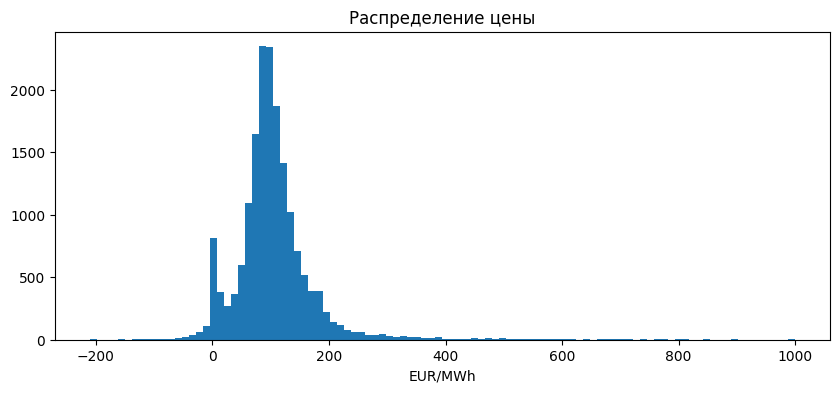

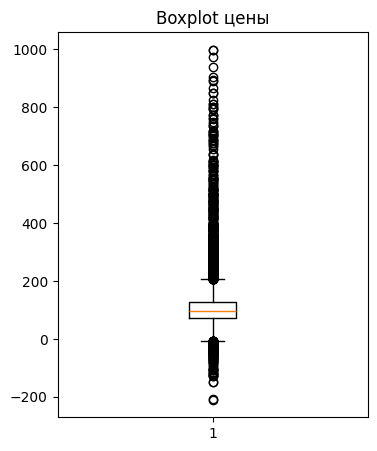

In [11]:
plt.figure(figsize=(10, 4))
plt.hist(price, bins=100)
plt.title('Распределение цены')
plt.xlabel('EUR/MWh')
plt.show()

plt.figure(figsize=(4, 5))
plt.boxplot(price)
plt.title('Boxplot цены')
plt.show()

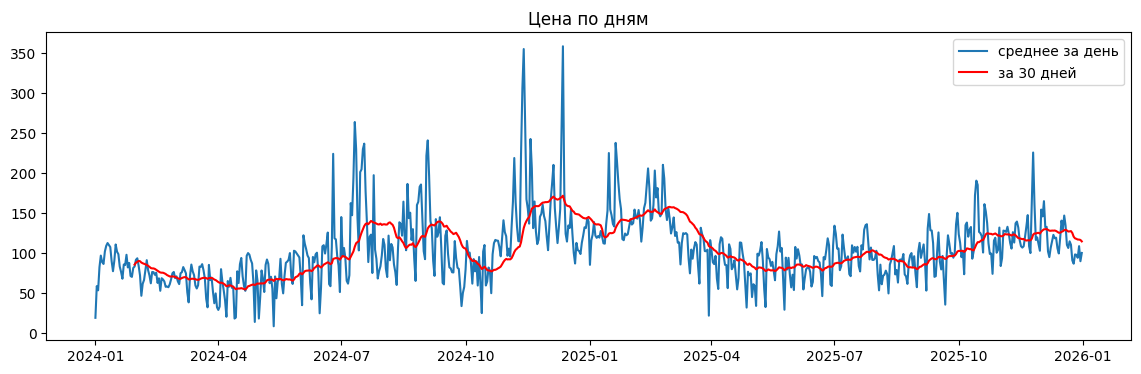

In [12]:
daily = df.set_index('time')['price_eur_mwh'].resample('D').mean()

plt.figure(figsize=(14, 4))
plt.plot(daily, label='среднее за день')
plt.plot(daily.rolling(30).mean(), color='red', label='за 30 дней')
plt.title('Цена по дням')
plt.legend()
plt.show()

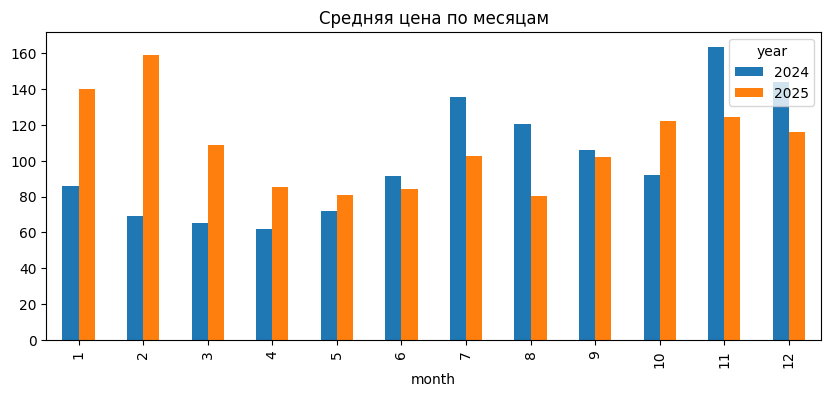

In [13]:
df.groupby(['month', 'year'])['price_eur_mwh'].mean().unstack().plot(kind='bar', figsize=(10, 4))
plt.title('Средняя цена по месяцам')
plt.show()

## Сезонность

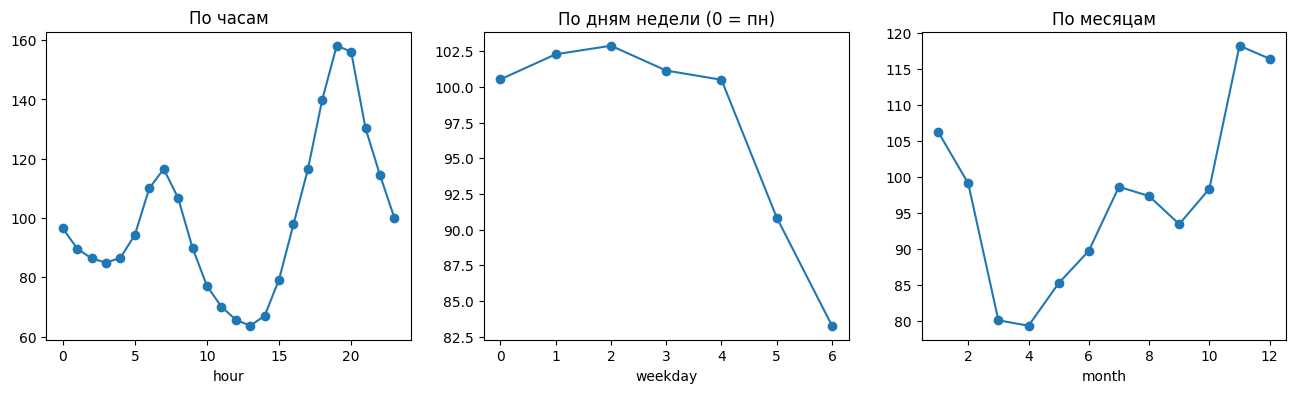

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

df.groupby('hour')['price_eur_mwh'].median().plot(ax=ax[0], marker='o')
ax[0].set_title('По часам')

df.groupby('weekday')['price_eur_mwh'].median().plot(ax=ax[1], marker='o')
ax[1].set_title('По дням недели (0 = пн)')

df.groupby('month')['price_eur_mwh'].median().plot(ax=ax[2], marker='o')
ax[2].set_title('По месяцам')

plt.show()

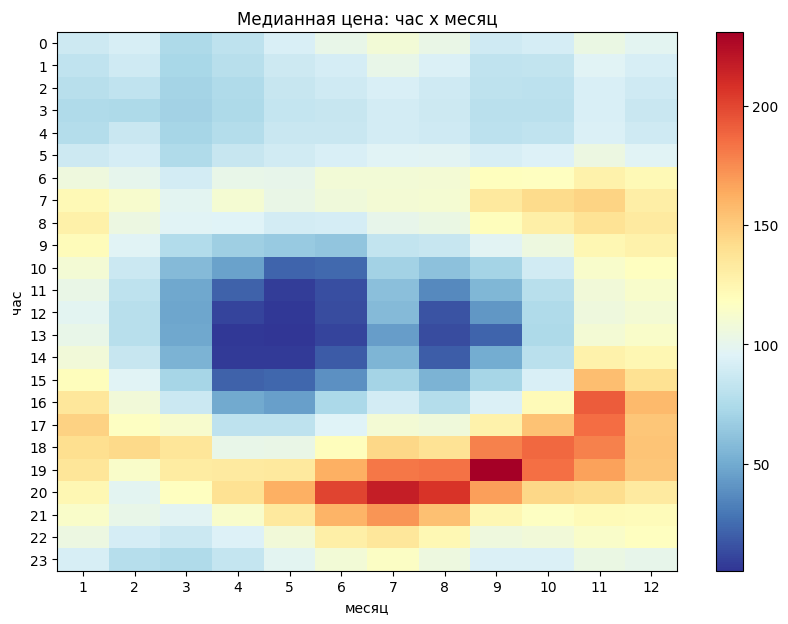

In [15]:
table = df.pivot_table(index='hour', columns='month', values='price_eur_mwh', aggfunc='median')

plt.figure(figsize=(10, 7))
plt.imshow(table, aspect='auto', cmap='RdYlBu_r')
plt.colorbar()
plt.xticks(range(12), range(1, 13))
plt.yticks(range(24))
plt.xlabel('месяц')
plt.ylabel('час')
plt.title('Медианная цена: час x месяц')
plt.show()

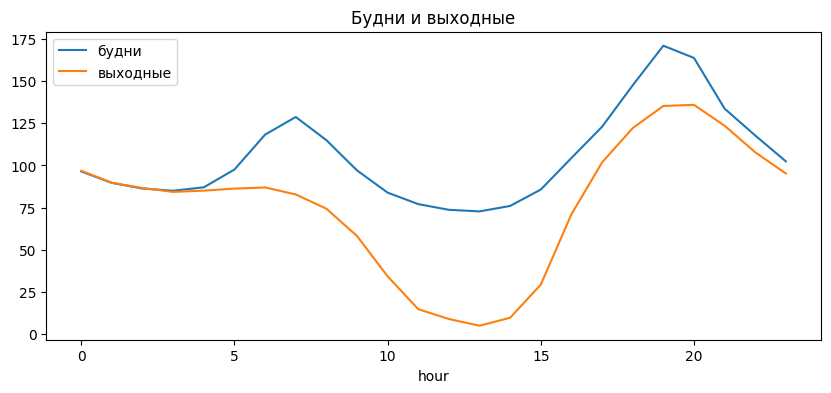

weekend
False    114.244185
True      80.556216
Name: price_eur_mwh, dtype: float64


In [16]:
plt.figure(figsize=(10, 4))
df[~df['weekend']].groupby('hour')['price_eur_mwh'].median().plot(label='будни')
df[df['weekend']].groupby('hour')['price_eur_mwh'].median().plot(label='выходные')
plt.legend()
plt.title('Будни и выходные')
plt.show()

print(df.groupby('weekend')['price_eur_mwh'].mean())

In [17]:
s = df.set_index('time')['price_eur_mwh']
print('автокорреляция 1 ч:', round(s.autocorr(1), 2))
print('автокорреляция 24 ч:', round(s.autocorr(24), 2))
print('автокорреляция 168 ч:', round(s.autocorr(168), 2))

автокорреляция 1 ч: 0.88
автокорреляция 24 ч: 0.78
автокорреляция 168 ч: 0.69


## Выбросы

In [18]:
q1 = price.quantile(0.25)
q3 = price.quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
print('границы:', low, high)

out = df[(price < low) | (price > high)]
print('выбросов:', len(out), round(len(out) / len(df) * 100, 1), '%')
print(out['hour'].value_counts().sort_index())

границы: -7.453749999999999 206.63625
выбросов: 1050 6.0 %
hour
0       3
6      11
7      42
8      32
9      18
10     21
11     37
12     50
13     60
14     62
15     59
16     69
17     85
18    126
19    156
20    149
21     50
22     12
23      8
Name: count, dtype: int64


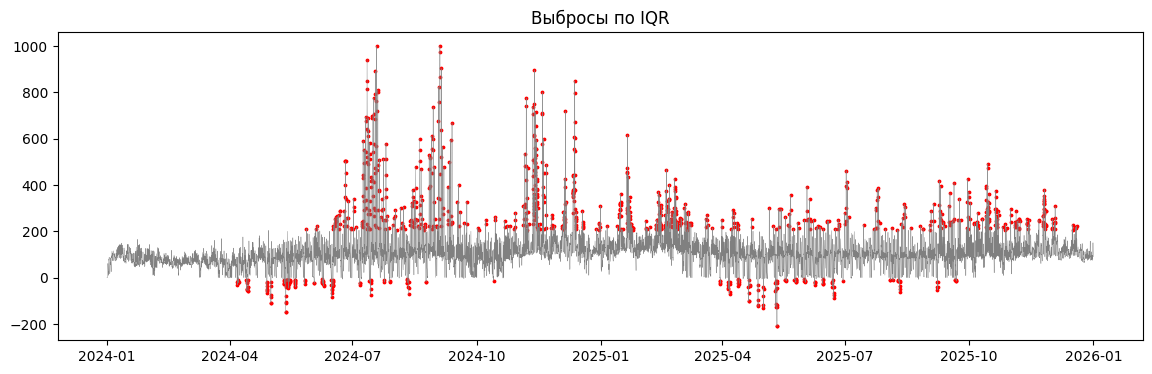

In [19]:
plt.figure(figsize=(14, 4))
plt.plot(df['time'], price, lw=0.3, color='grey')
plt.scatter(out['time'], out['price_eur_mwh'], s=3, color='red')
plt.title('Выбросы по IQR')
plt.show()

In [20]:
cols = ['time', 'price_eur_mwh', 'demand_forecast_mwh', 'solar_forecast_mwh',
        'nuclear_forecast_mwh', 'residual_load', 'net_exchange_forecast_mwh']
df.sort_values('price_eur_mwh', ascending=False)[cols].head(10)

,time,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,nuclear_forecast_mwh,residual_load,net_exchange_forecast_mwh
4795,2024-07-18 20:00:00+02:00,999.01,6720.93,18.78,1900.0,4723.87,-600.0
5922,2024-09-03 19:00:00+02:00,999.00,6538.58,15.43,1428.0,5060.05,-200.0
5923,2024-09-03 20:00:00+02:00,974.80,6426.08,0.00,1428.0,4949.95,-200.0
4627,2024-07-11 20:00:00+02:00,940.16,6570.58,20.18,1900.0,4577.00,-600.0
5946,2024-09-04 19:00:00+02:00,903.41,6555.33,12.00,1428.0,5065.65,-200.0
7601,2024-11-12 17:00:00+01:00,895.20,6767.53,0.00,1900.0,4862.43,-4328.9
4772,2024-07-17 21:00:00+02:00,891.37,6467.23,0.00,1900.0,4489.65,-600.0
5921,2024-09-03 18:00:00+02:00,867.51,6480.93,208.75,1428.0,4823.43,-200.0
4626,2024-07-11 19:00:00+02:00,850.05,6616.53,190.65,1900.0,4468.20,-600.0
8321,2024-12-12 17:00:00+01:00,850.00,6880.78,0.00,1900.0,4958.78,-2593.0


In [21]:
df.sort_values('price_eur_mwh')[cols].head(10)

,time,price_eur_mwh,demand_forecast_mwh,solar_forecast_mwh,nuclear_forecast_mwh,residual_load,net_exchange_forecast_mwh
11917,2025-05-11 14:00:00+02:00,-210.05,3255.70,2914.93,1900.0,-1590.98,1709.0
11916,2025-05-11 13:00:00+02:00,-207.92,3191.15,2471.60,1900.0,-1210.85,1444.2
3181,2024-05-12 14:00:00+02:00,-149.98,3086.43,2916.33,1424.0,-1267.90,1800.0
3180,2024-05-12 13:00:00+02:00,-149.97,2986.83,2866.50,1424.0,-1321.30,1800.0
11676,2025-05-01 13:00:00+02:00,-129.07,2385.30,3339.40,1900.0,-2875.98,3207.7
11915,2025-05-11 12:00:00+02:00,-127.30,3441.95,1925.30,1900.0,-412.30,1147.5
11892,2025-05-10 13:00:00+02:00,-125.21,2806.00,3349.10,1900.0,-2447.83,2855.9
11580,2025-04-27 13:00:00+02:00,-124.63,2854.35,3553.98,1900.0,-2612.41,2855.3
11677,2025-05-01 14:00:00+02:00,-119.46,2415.23,3513.10,1900.0,-3017.82,3183.5
11581,2025-04-27 14:00:00+02:00,-117.68,2927.68,4036.68,1900.0,-3022.38,2851.9


In [22]:
# чем отличаются часы с ценой <= 0 (только дневные, иначе нечестно сравнивать)
day = df[(df['hour'] >= 10) & (df['hour'] <= 16)]
print(day.groupby(day['price_eur_mwh'] <= 0)[['demand_forecast_mwh', 'solar_forecast_mwh',
                                               'residual_load', 'net_exchange_forecast_mwh']].median())
print('доля выходных среди цен <= 0:', round(df[price <= 0]['weekend'].mean(), 2))

               demand_forecast_mwh  solar_forecast_mwh  residual_load  \
price_eur_mwh                                                           
False                     4902.230             1710.05       1352.520   
True                      3757.855             2853.35       -833.305   

               net_exchange_forecast_mwh  
price_eur_mwh                             
False                             -200.0  
True                              1000.0  
доля выходных среди цен <= 0: 0.81


## Связь с признаками

In [23]:
features = ['price_eur_mwh', 'demand_forecast_mwh', 'solar_forecast_mwh', 'wind_forecast_mwh',
            'nuclear_forecast_mwh', 'temperature_forecast_c', 'net_exchange_forecast_mwh', 'residual_load']

corr = df[features].corr(method='spearman')
corr['price_eur_mwh'].sort_values()

net_exchange_forecast_mwh   -0.532057
solar_forecast_mwh          -0.338226
temperature_forecast_c      -0.242036
wind_forecast_mwh           -0.077029
nuclear_forecast_mwh         0.109935
demand_forecast_mwh          0.662393
residual_load                0.693064
price_eur_mwh                1.000000
Name: price_eur_mwh, dtype: float64

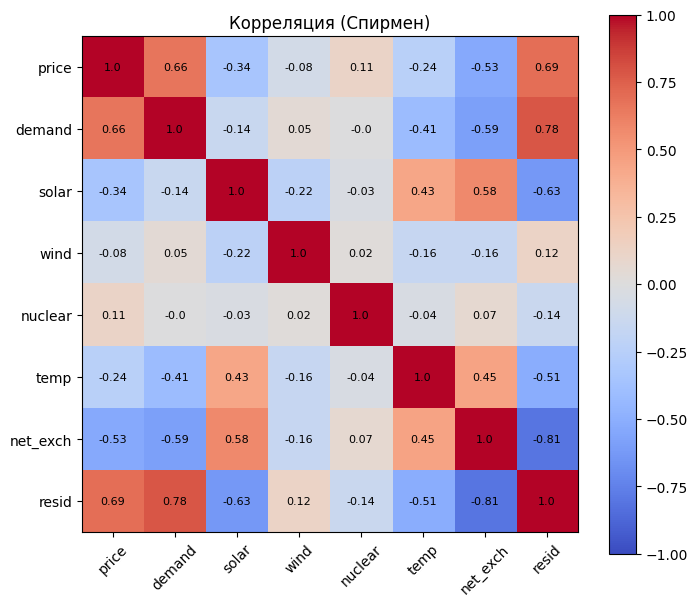

In [24]:
plt.figure(figsize=(8, 7))
plt.imshow(corr, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()
names = ['price', 'demand', 'solar', 'wind', 'nuclear', 'temp', 'net_exch', 'resid']
plt.xticks(range(len(names)), names, rotation=45)
plt.yticks(range(len(names)), names)
for i in range(len(names)):
    for j in range(len(names)):
        plt.text(j, i, round(corr.iloc[i, j], 2), ha='center', va='center', fontsize=8)
plt.title('Корреляция (Спирмен)')
plt.show()

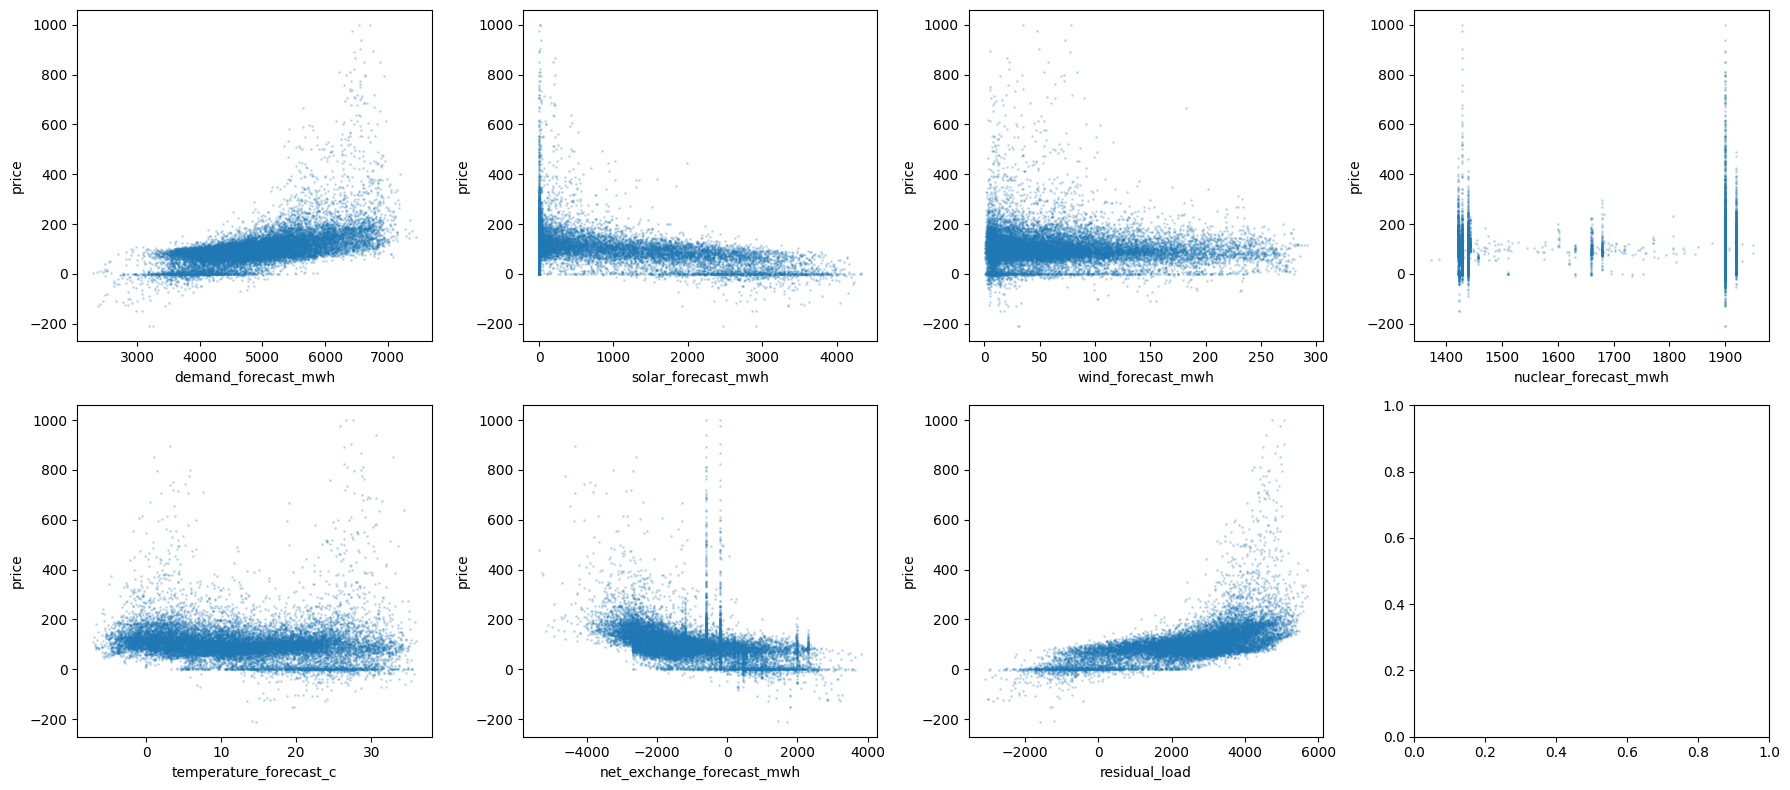

In [25]:
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
ax = ax.flatten()
for i, col in enumerate(features[1:]):
    ax[i].scatter(df[col], df['price_eur_mwh'], s=1, alpha=0.2)
    ax[i].set_xlabel(col)
    ax[i].set_ylabel('price')
plt.tight_layout()
plt.show()

In [26]:
# с температурой связь не линейная, смотрю средние по интервалам
df['temp_bin'] = pd.cut(df['temperature_forecast_c'], bins=range(-10, 40, 3))
df.groupby('temp_bin', observed=True)[['price_eur_mwh', 'demand_forecast_mwh']].mean()

,price_eur_mwh,demand_forecast_mwh
temp_bin,,
"(-10, -7]",110.570000,6197.250000
"(-7, -4]",115.538323,5535.504000
"(-4, -1]",125.674913,5418.554706
"(-1, 2]",133.648583,5575.985122
"(2, 5]",127.729278,5571.373095
"(5, 8]",105.261426,5218.043950
"(8, 11]",101.630536,4988.984007
"(11, 14]",93.361225,4716.679440
"(14, 17]",86.457501,4489.676620


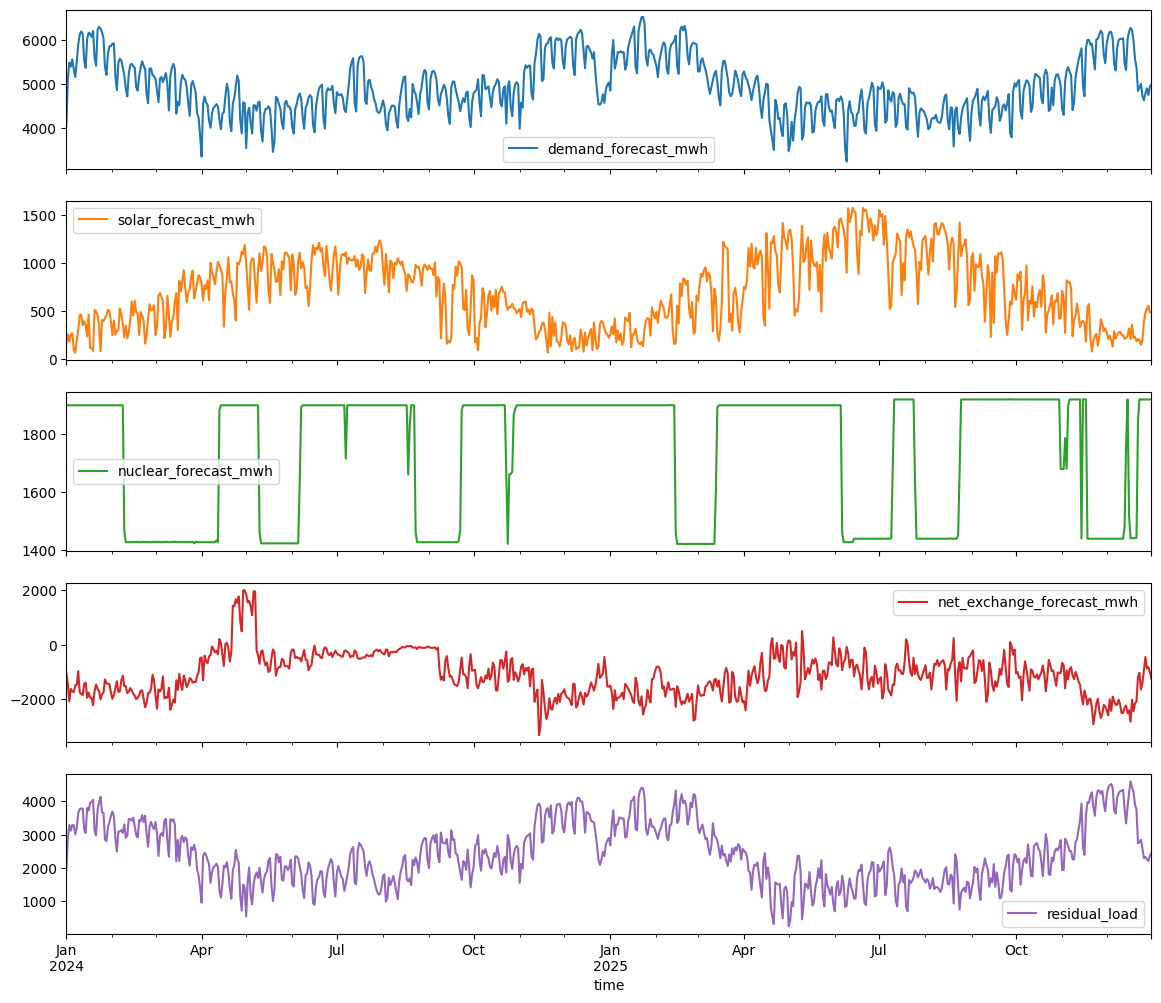

In [27]:
d = df.set_index('time')[['demand_forecast_mwh', 'solar_forecast_mwh', 'nuclear_forecast_mwh',
                          'net_exchange_forecast_mwh', 'residual_load']].resample('D').mean()
d.plot(subplots=True, figsize=(14, 12))
plt.show()

## Выводы

1. Данные чистые: 17544 часа, без пропусков и дублей. Странно выглядит net_exchange летом 2024: много одинаковых круглых значений (-200, -600).

2. Медиана цены около 98 EUR/MWh, среднее 105. Есть сильные выбросы вверх (до 999) и отрицательные цены (до -210), цена <= 0 примерно в 3.7% часов.

3. Сильная сезонность:
   - днём цена падает из-за солнца, вечером (19-20 ч) пик;
   - весной в полдень медиана почти 0;
   - в выходные цена примерно на 30% ниже;
   - дороже всего ноябрь, дешевле всего апрель;
   - автокорреляция на 24 ч и 168 ч высокая (0.78 и 0.69), то есть есть суточный и недельный цикл.

4. Выбросы реальные, это не ошибки: дорогие часы приходятся на вечера с большим спросом и без солнца (иногда АЭС на ремонте), дешёвые на солнечные выходные весной. Удалять их не стал.

5. Связи с ценой:
   - сильнее всего остаточная нагрузка (0.69) и спрос (0.66);
   - солнце и net_exchange дают минус: больше солнца и экспорта, ниже цена;
   - ветер и АЭС почти не влияют (ветра в Венгрии мало, АЭС почти константа);
   - температура влияет через спрос: дороже и в холод, и в жару.

6. Чего не хватает: цены на газ и цен соседних стран. Скорее всего, из-за газа начало 2025 дороже, чем 2024.